# Band-aligned CTL summary — `plot_multi_mat_ctl`

`plot_multi_mat_ctl` puts the transition levels of several defects in one or more materials on a single band-alignment diagram:

- Each material is a block of columns, one column per defect.
- VB (green) and CB (orange) shading is placed using each material's conduction band offset. Faded strips show the cell-to-cell spread of the band edges.
- Each thermodynamic transition is coloured by charge state. With one site it is a single line; with several sites/cells it is a bar showing **min / mean / max** across sites.
- Transitions bypassed by a negative-U level can be shown as faint dashed marks.
- Optional horizontal Fermi level guides.

CTLs are calculated per site, against that site's own cell. They are only collected into a distribution after that, so charge states from different sites are never mixed.

> **All data in this notebook are synthetic** (see `data/make_example_data.py`), so some plots may look odd.

In [1]:
import csv
from cp2k_utils.ctl import (Defect, Cell, Material, CTL, FermiLevel, StyleOptions,
                            load_defects_csv, plot_multi_mat_ctl)

## 1. Single CTL values: crystalline hosts

The simplest case is one cell with one site per defect, like the input to `plot_ctl`. Each transition then has exactly one value and is drawn as a **single line**, not a range bar.

Here the crystalline defects from `plot_ctl.ipynb` are loaded from `data/crystalline_defects.csv`, which already has the `material` column set. The only other thing needed is a `Material` holding the one `Cell`.

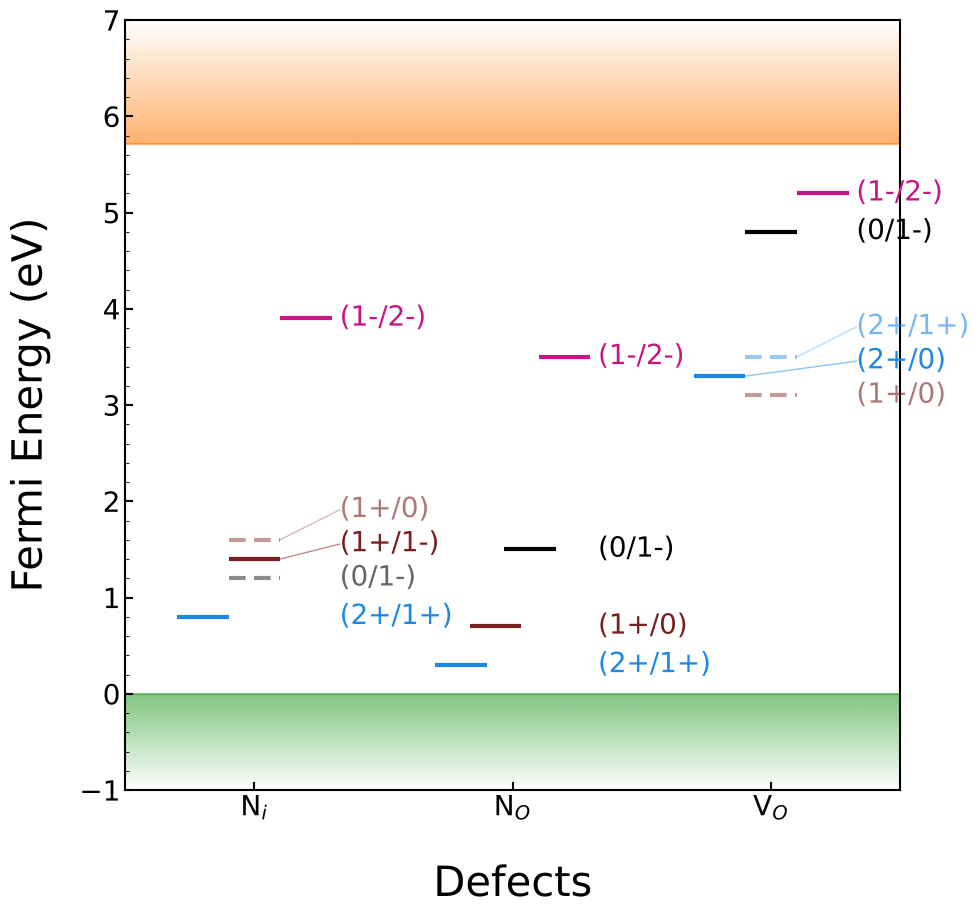

In [2]:
crystal_defects = load_defects_csv('data/crystalline_defects.csv')

c_hfo2 = Material('c-HfO2', title='m-HfO$_2$',
                  cells=[Cell('bulk', vbm=0.25, cbm=0.46, bulk=-1000.0)])

fig, ax, _ = plot_multi_mat_ctl(crystal_defects, [c_hfo2], style=StyleOptions(figsize=(10, 10)))

The dashed, faded marks for N$_i$ (and V$_O$) are the transitions through the skipped charge state, because (1+/1-) (and (2+/0)) are negative-U transitions. `StyleOptions(show_bypassed=False)` hides them.

### Several crystalline materials

Single values work the same way across materials. Below, the crystalline HfO$_2$ results are put next to a second material whose levels are supplied directly as `CTL` objects (see section 4). Its `Cell` only needs band edges; `bulk` is not used when every defect comes from `precomputed_ctls`.

> The second material's values are **made up** for the example.

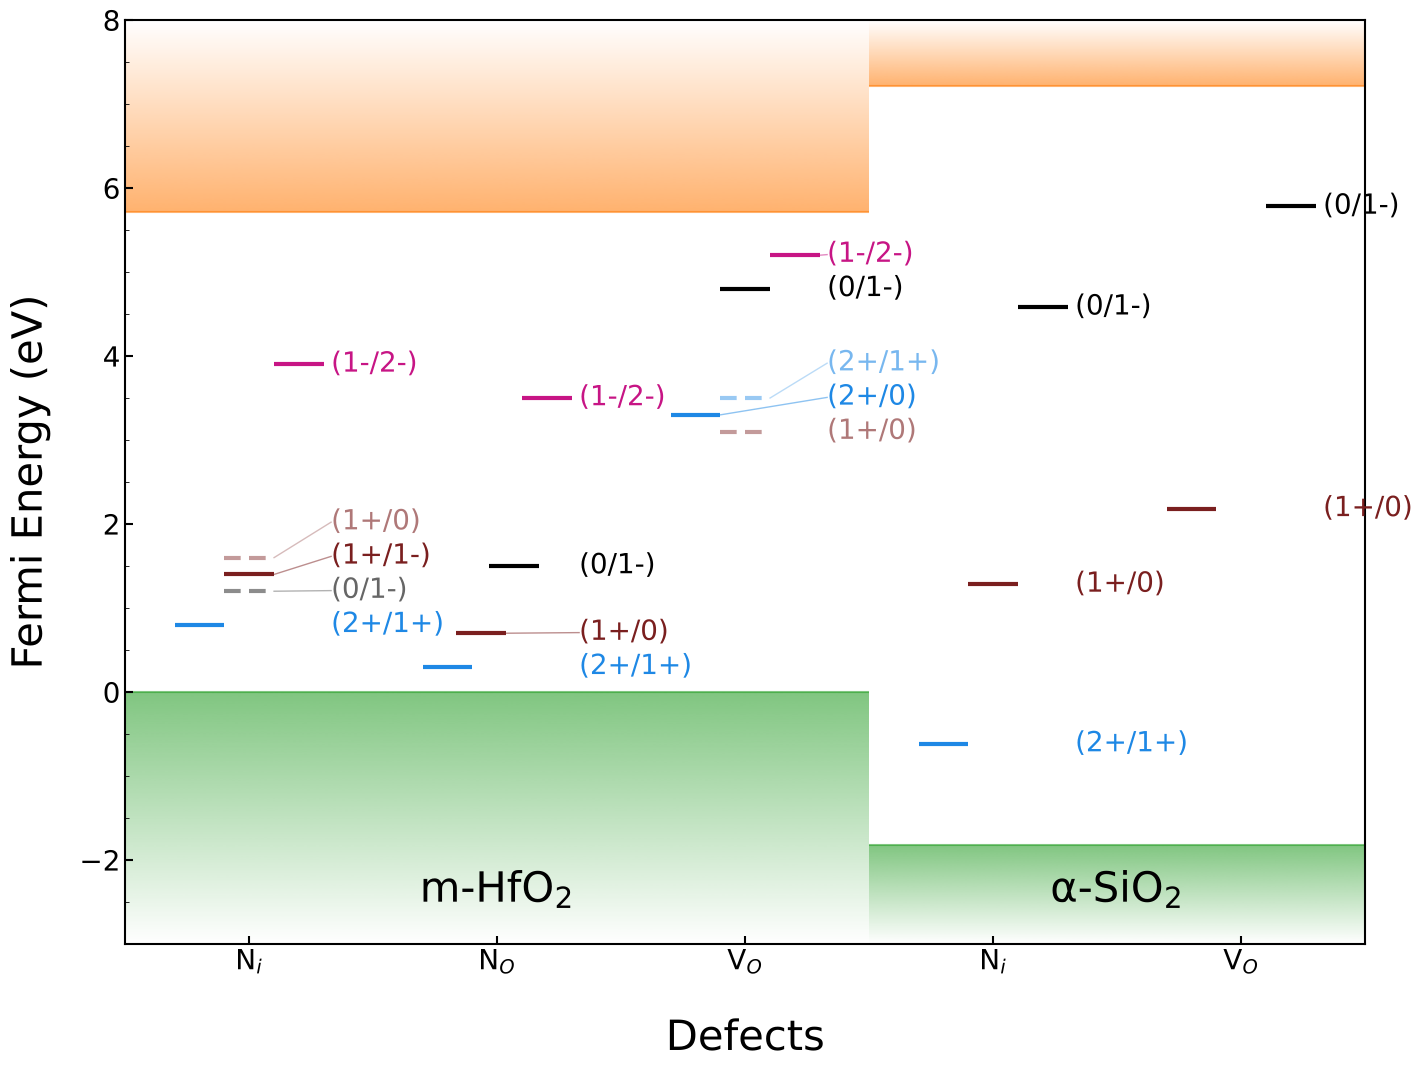

In [3]:
c_sio2 = Material('c-SiO2', title='α-SiO$_2$', offset=1.5,
                  cells=[Cell('bulk', vbm=0.2010, cbm=0.5330, bulk=0.0)])

sio2_ctls = {
    'c-SiO2': {
        'N$_i$':  [CTL('(2+/1+)', 1.2), CTL('(1+/0)', 3.1), CTL('(0/1-)', 6.4)],
        'V$_O$':  [CTL('(1+/0)', 4.0), CTL('(0/1-)', 7.6)],
    },
}

fig, ax, _ = plot_multi_mat_ctl(crystal_defects, [c_hfo2, c_sio2],
                                precomputed_ctls=sio2_ctls,
                                style=StyleOptions(figsize=(16, 12)))

## 2. Ranges over many sites: amorphous hosts

With several cells and sites per defect, each transition becomes a **distribution**. By default it is drawn as a bar showing the min, mean and max across sites; section 2.1 shows other ways to draw it.

A site only counts towards a transition's distribution if that transition is a real (thermodynamic) level at that site. Where it is bypassed by a negative-U level, the value goes into a separate `bypassed_values` list and is drawn as a faded dashed mark.

The band shading follows the same idea as `plot_range_ctl`. It is solid up to the band edge that every cell agrees on, and a **hatched strip** shows the range of the band edge across the cells. The thin solid line is the mean band edge.

### Materials and band offsets

Every `Defect` must have `material` set to the `name` of one of the `Material` objects.

`Material.offset` is the **conduction band offset (eV)** of that material compared with a reference material:
- The reference material has `offset=0`, and its VBM is drawn at y = 0.
- Each other material's CBM is placed `offset` eV above the reference CBM (negative is below). Its VBM is then placed using its own band gap.
- The reference is found automatically as the material with `offset == 0`. `reference='<name>'` chooses it explicitly; that material should also have `offset=0`.
- `title` changes how the material is labelled on the plot. Without it, digits in `name` are subscripted automatically (`HfO2` → HfO$_2$).

In [4]:
cells = {}
with open('data/amorphous_cells.csv') as fh:
    for row in csv.DictReader(fh):
        cells.setdefault(row['material'], []).append(
            Cell(row['cell_id'], float(row['vbm']), float(row['cbm']), float(row['bulk'])))

materials = [
    Material('HfO2', title='a-HfO$_2$', cells=cells['HfO2'], offset=0.0),
    Material('SiO2', title='a-SiO$_2$', cells=cells['SiO2'], offset=1.5),   # CB 1.5 eV above HfO2's
]
for m in materials:
    print(f'{m.name}: gap {m.mean_gap_eV:.2f} eV, VBM spread {[round(x, 2) for x in m.vbm_spread_eV]} eV')

defects = load_defects_csv('data/amorphous_defects.csv')

HfO2: gap 5.65 eV, VBM spread [6.76, 6.97] eV
SiO2: gap 9.12 eV, VBM spread [5.2, 5.59] eV


### Basic plot

| argument | default | |
|---|---|---|
| `style_kind` | `'bar'` | how distributions are drawn: `'bar'`, `'violin'` or `'strip'` (section 2.1) |
| `fermi_lines` | `None` | a number, a `FermiLevel`, or a list of `FermiLevel`, on the displayed axis |
| `reference` | `None` | name of the reference material (VBM at y = 0) |
| `precomputed_ctls` | `None` | add CTLs from elsewhere (section 4) |
| `xlabel` | `True` | draw the 'Defects' x-axis label |
| `style` | `None` | `StyleOptions` |
| `save`, `filename` | `False`, `'Multi_Mat_CTLs.png'` | |
| `show` | `True` | |

It returns `(fig, ax, distributions)`.

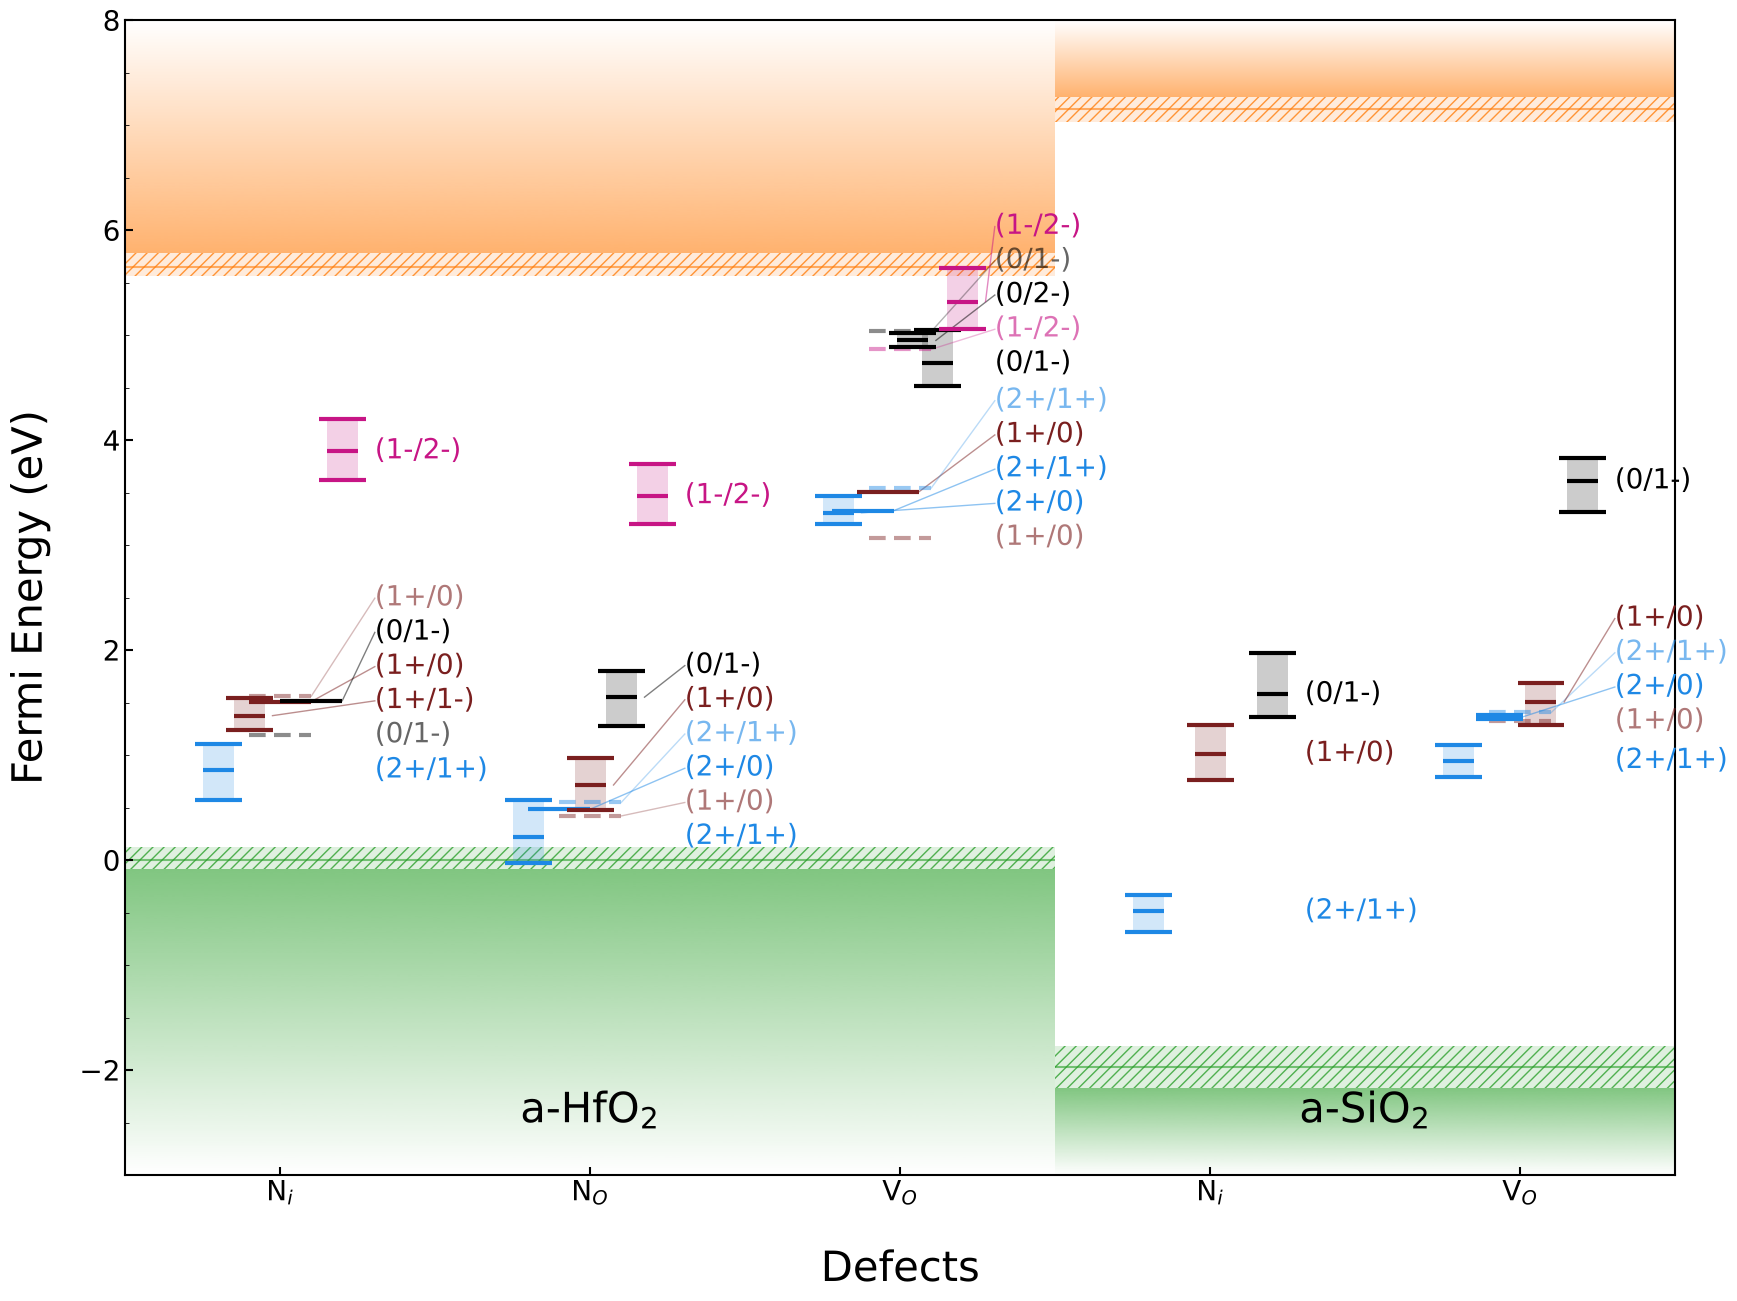

In [5]:
fig, ax, dist = plot_multi_mat_ctl(defects, materials)

`distributions[material][defect][transition]` holds the per-site values (eV above that material's VBM), so you can analyse them directly:

Each entry has `values` (sites where it is a real level), `bypassed_values`, `kind` and `n_sites`, the number of site/cell configurations of that defect. A transition that appears at only a few sites is still drawn, so check `n` against `n_sites`.

In [6]:
import numpy as np
for mat, dmap in dist.items():
    for dname, trans in dmap.items():
        for tr, entry in trans.items():
            v = np.array(entry['values'])
            n_b = len(entry['bypassed_values'])
            if len(v):
                print(f"{mat:5} {dname:4} {tr:>8}  mean {v.mean():5.2f}  range {v.min():5.2f} to {v.max():5.2f} eV"
                      f"  real at {len(v):2d}/{entry['n_sites']} sites, bypassed at {n_b}")
            else:
                print(f"{mat:5} {dname:4} {tr:>8}  bypassed at {n_b}/{entry['n_sites']} sites")

HfO2  N_i   (2+/1+)  mean  0.85  range  0.58 to  1.11 eV  real at 24/24 sites, bypassed at 0
HfO2  N_i   (1+/1-)  mean  1.38  range  1.24 to  1.54 eV  real at 23/24 sites, bypassed at 0
HfO2  N_i    (1+/0)  mean  1.51  range  1.51 to  1.51 eV  real at  1/24 sites, bypassed at 23
HfO2  N_i    (0/1-)  mean  1.52  range  1.52 to  1.52 eV  real at  1/24 sites, bypassed at 23
HfO2  N_i   (1-/2-)  mean  3.89  range  3.62 to  4.20 eV  real at 24/24 sites, bypassed at 0
HfO2  N_O   (2+/1+)  mean  0.22  range -0.03 to  0.57 eV  real at 23/24 sites, bypassed at 1
HfO2  N_O    (1+/0)  mean  0.71  range  0.48 to  0.97 eV  real at 23/24 sites, bypassed at 1
HfO2  N_O    (0/1-)  mean  1.55  range  1.27 to  1.80 eV  real at 24/24 sites, bypassed at 0
HfO2  N_O   (1-/2-)  mean  3.47  range  3.20 to  3.77 eV  real at 24/24 sites, bypassed at 0
HfO2  N_O    (2+/0)  mean  0.48  range  0.48 to  0.48 eV  real at  1/24 sites, bypassed at 0
HfO2  V_O    (2+/0)  mean  3.31  range  3.20 to  3.47 eV  real at 23

### 2.1 Showing the distribution: `style_kind`

The min / mean / max bar hides how the values are spread inside the range. `style_kind` changes how each distribution is drawn:

| `style_kind` | draws | good for |
|---|---|---|
| `'bar'` (default) | min, mean and max lines with a shaded band | compact summaries |
| `'violin'` | a smoothed density of the values (Gaussian KDE, cut at min/max), with mean line and min/max ticks | showing where most sites lie |
| `'strip'` | one thin line per site, plus the mean in bold | seeing every value; data exploration rather than publication |

A transition with a single value is always a single line.

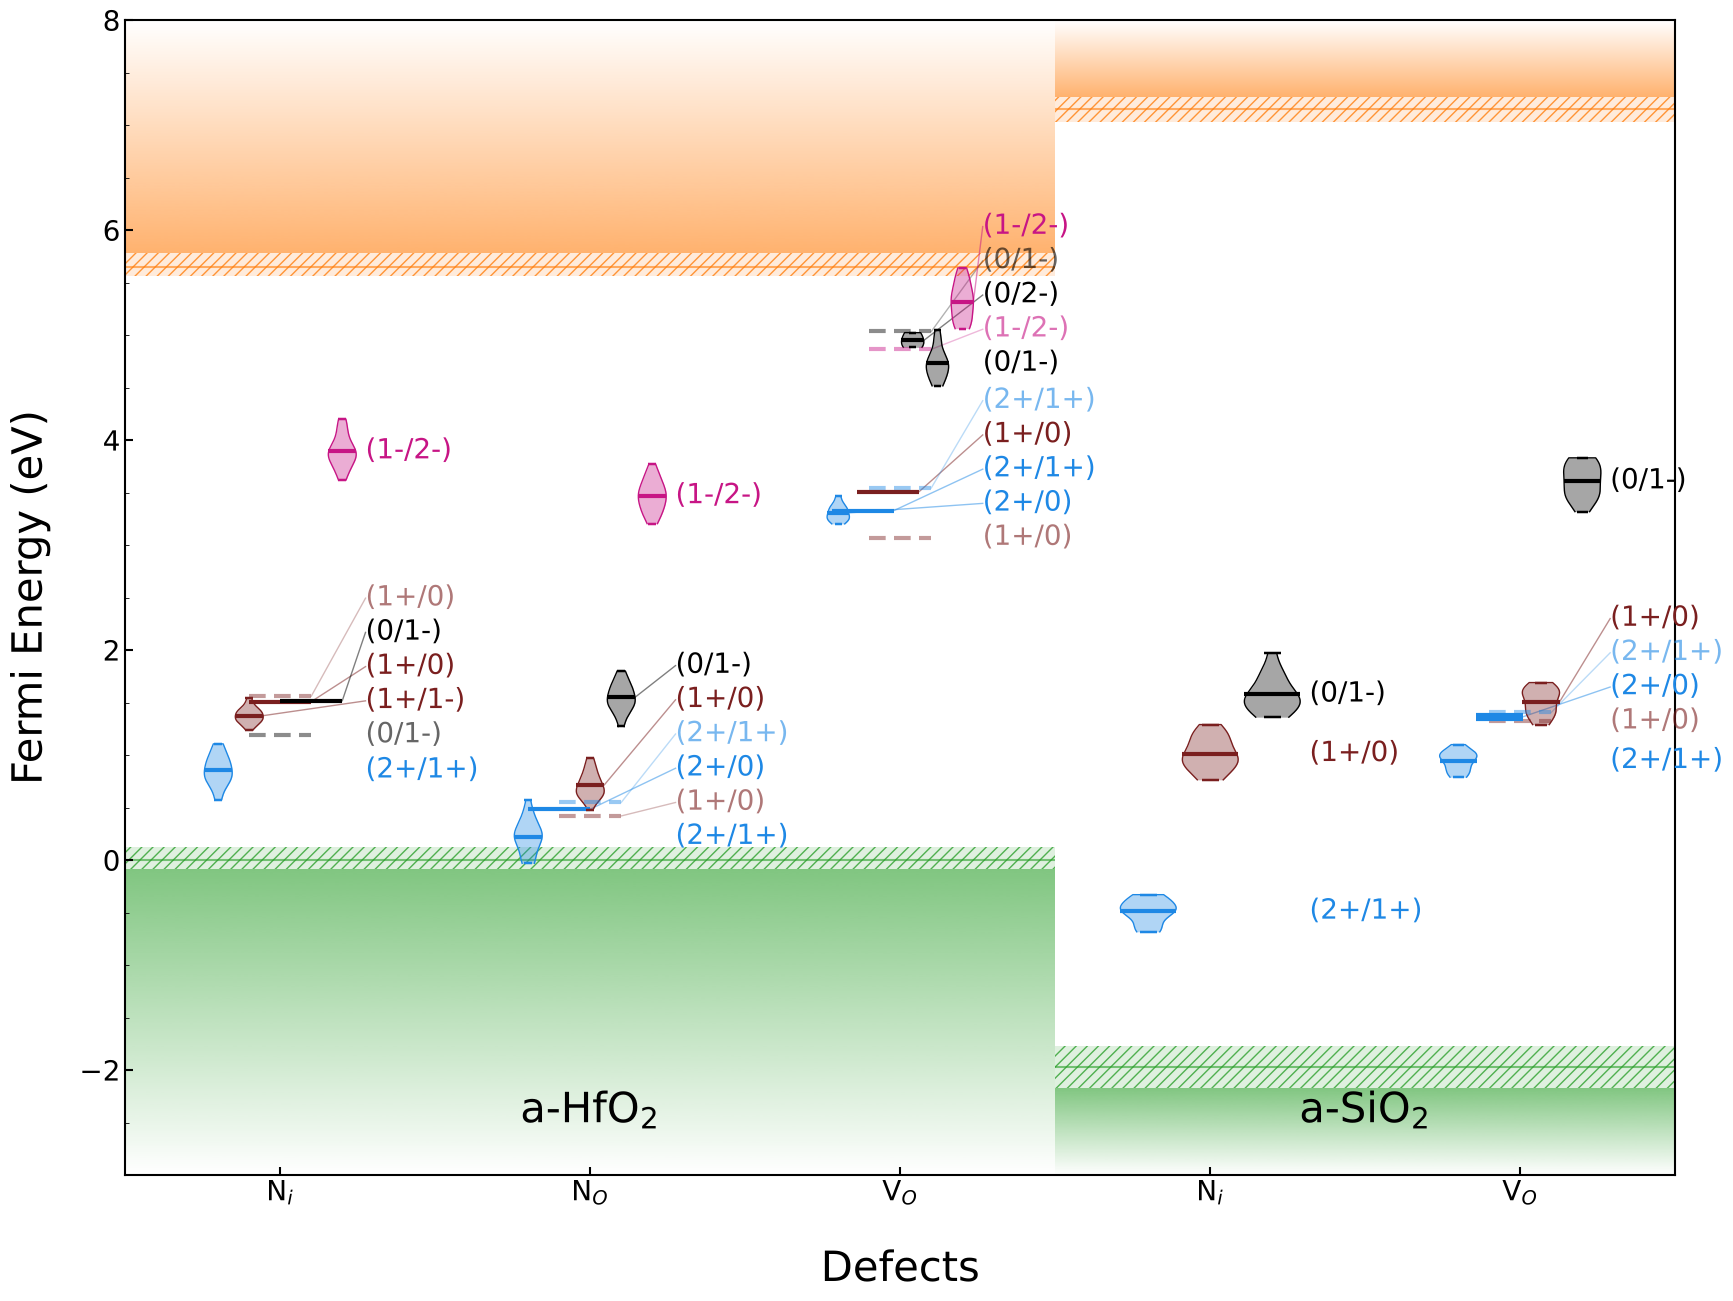

In [7]:
fig, ax, _ = plot_multi_mat_ctl(defects, materials, style_kind='violin')

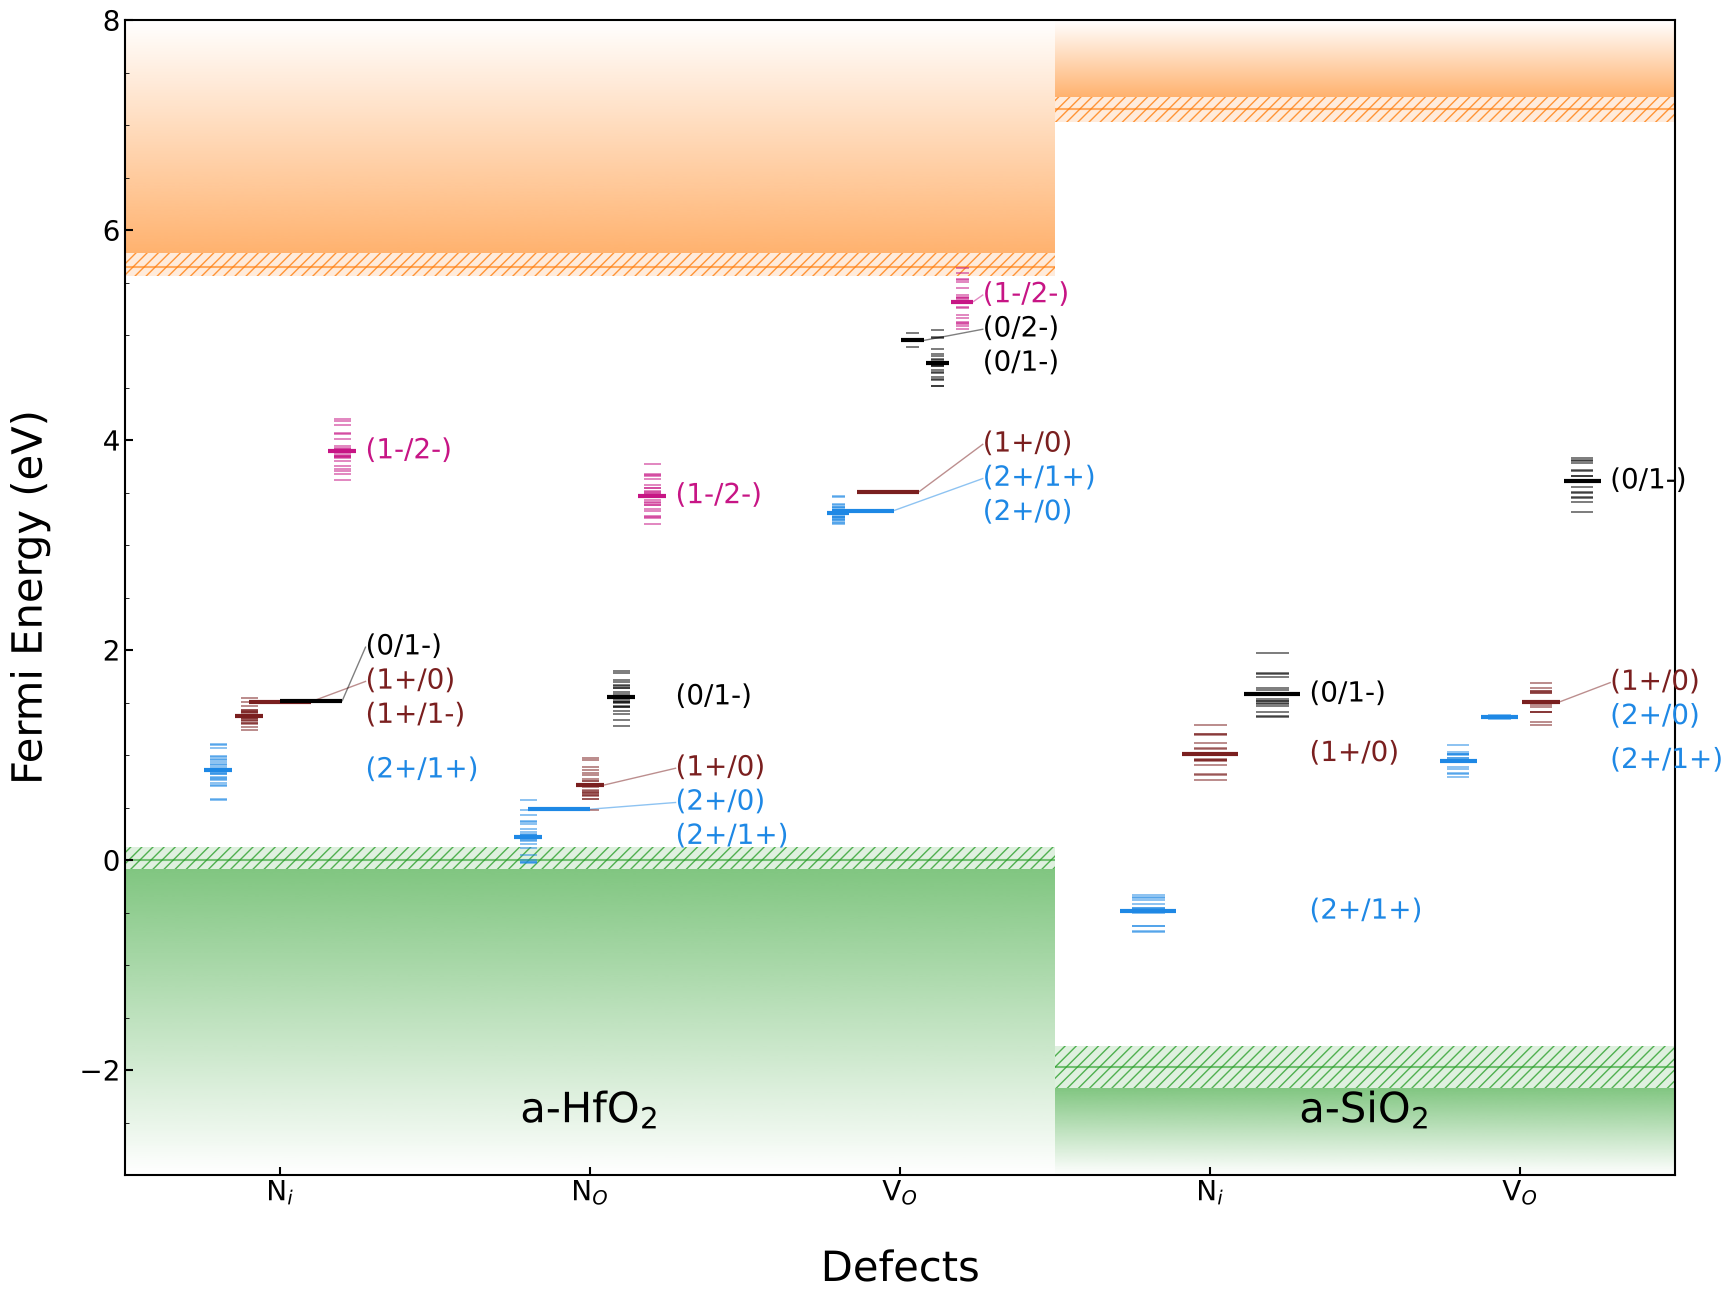

In [8]:
fig, ax, _ = plot_multi_mat_ctl(defects, materials, style_kind='strip',
                                style=StyleOptions(show_bypassed=False))

## 3. Fermi levels and styling

`FermiLevel(label, energy, colour=None)` draws a dashed horizontal line. `energy` is on the displayed axis, so it is measured from the reference material's VBM.

`StyleOptions` fields that apply to this plot:

| option | default | |
|---|---|---|
| `figsize`, `title` | `(20, 15)`, `None` | |
| `legend`, `legend_fontsize` | `False`, `20` | legend (outside the axes, on the right) of transitions, Fermi lines and band-edge range |
| `annotate_ctls`, `ctl_label_fontsize` | `True`, `20` | text labels next to each bar, spaced so they don't overlap |
| `leader_linewidth` | `1.0` | lines linking moved labels to their bars |
| `ctl_linewidth` | `3` | |
| `ctl_colour` | `None` | one colour for every transition instead of colouring by charge |
| `show_bypassed`, `bypassed_alpha`, `bypassed_linewidth` | `True`, `0.45`, `None` | |
| `band_edge_lines`, `band_alpha` | `True`, `0.6` | mean band edge lines; shading opacity |
| `show_edge_spread`, `edge_spread_hatch` | `True`, `'///'` | hatched band-edge range across cells |
| `violin_alpha`, `strip_alpha` | `0.35`, `0.6` | for `style_kind='violin'` / `'strip'` |
| `show_material_labels`, `mats_fontsize` | auto (only if >1 material), `30` | |
| `axes_fontsize`, `ticks_fontsize` | `30`, `20` | |

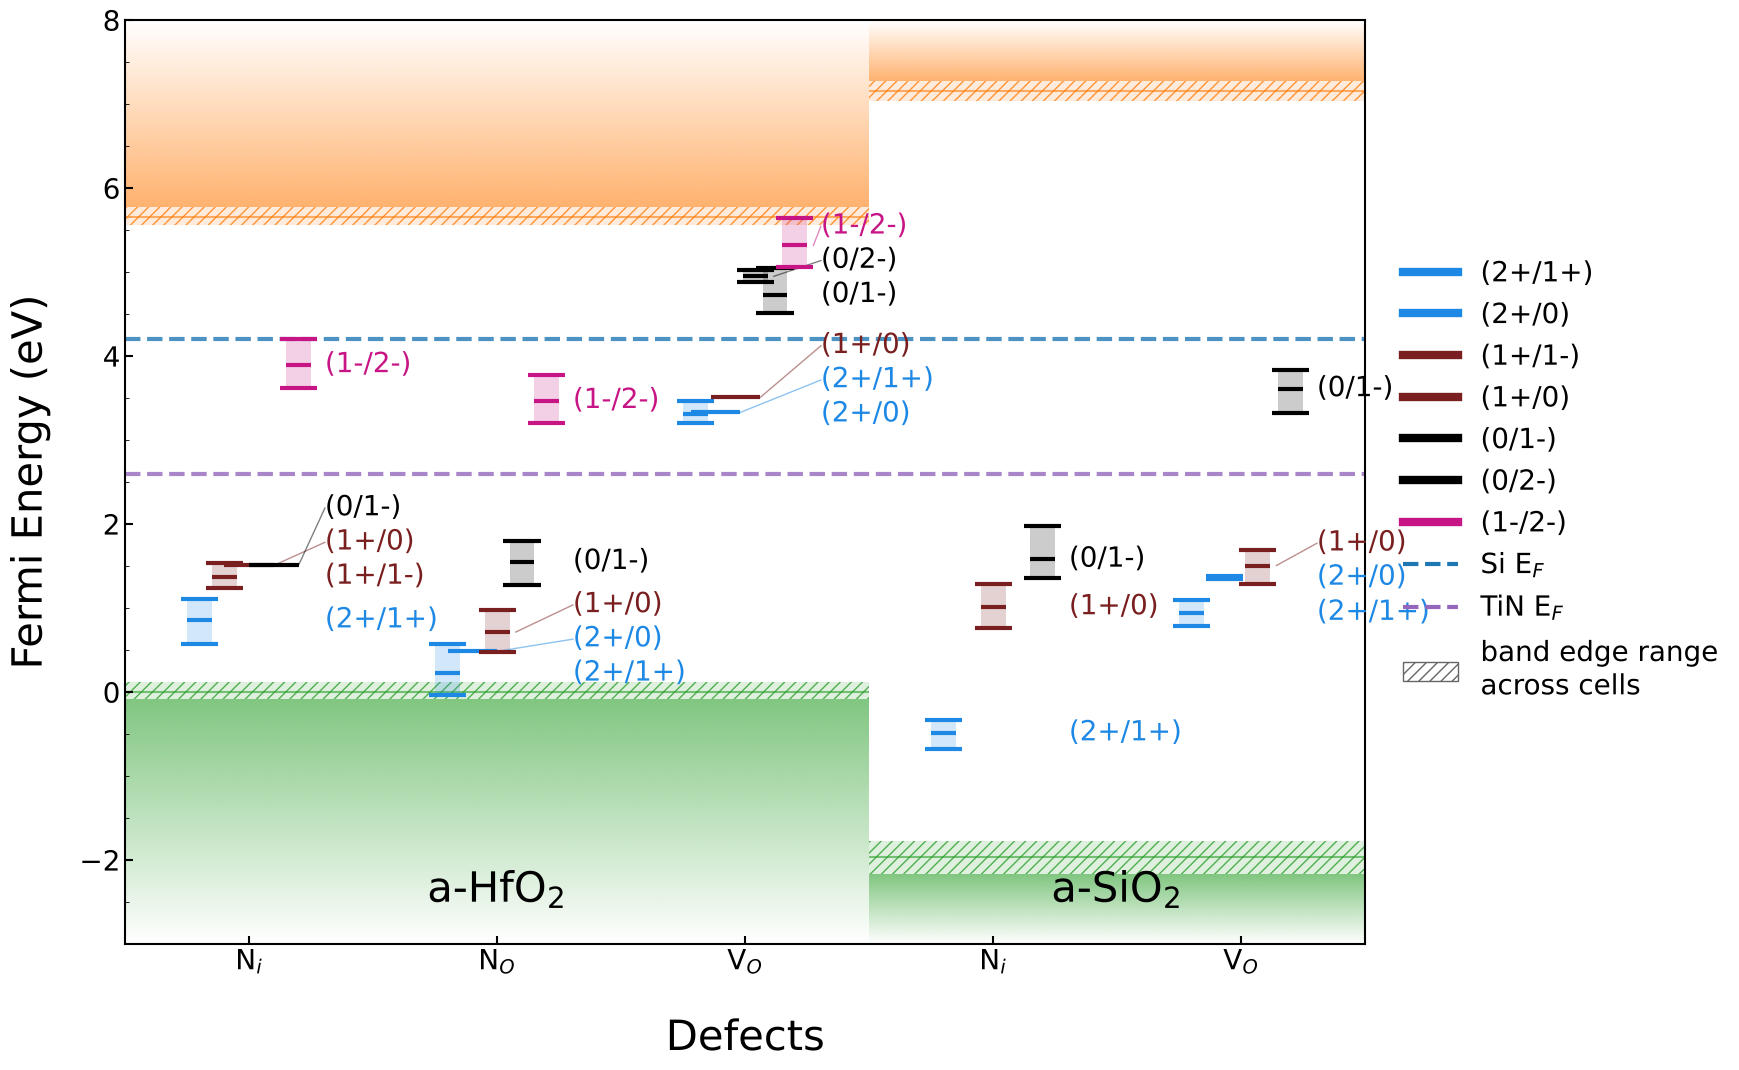

In [9]:
style = StyleOptions(
    figsize=(16, 12),
    legend=True,
    show_bypassed=False,
)

fermi = [
    FermiLevel('Si E$_F$', 4.2, colour='tab:blue'),
    FermiLevel('TiN E$_F$', 2.6, colour='tab:purple'),
]

fig, ax, _ = plot_multi_mat_ctl(defects, materials, fermi_lines=fermi, style=style)

### Single material

With only one material the material label is hidden automatically. Offsets are measured from the reference material, so a material plotted on its own should have `offset=0`.

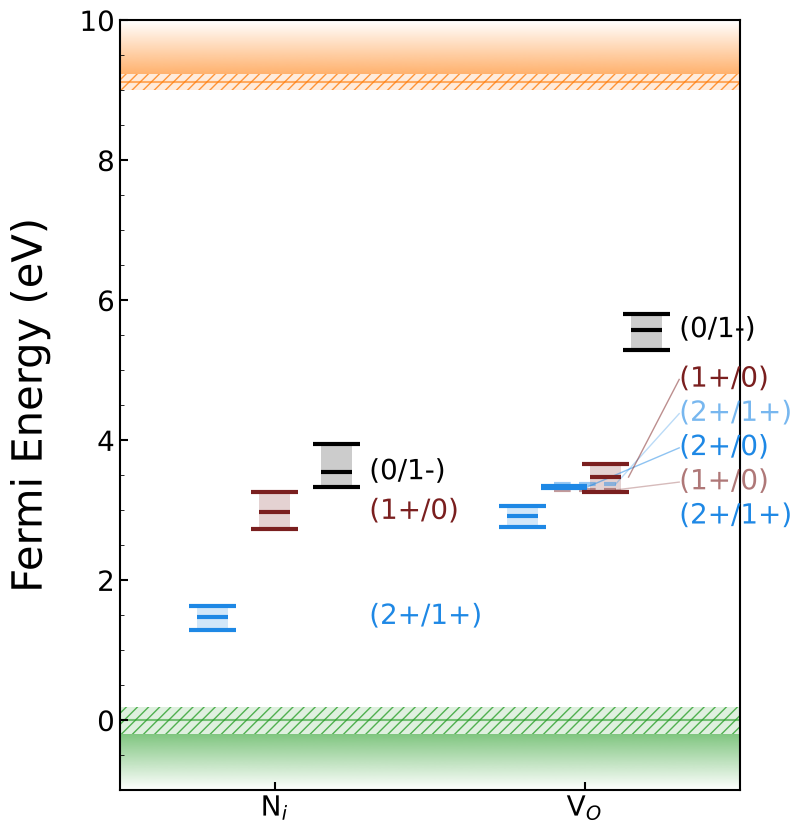

In [10]:
sio2 = Material('SiO2', title='a-SiO$_2$', cells=cells['SiO2'])   # offset defaults to 0
sio2_only = [d for d in defects if d.material == 'SiO2']

fig, ax, _ = plot_multi_mat_ctl(sio2_only, [sio2], style=StyleOptions(figsize=(8, 10)), xlabel=False)

## 4. Adding CTLs calculated elsewhere

`precomputed_ctls` lets you include transition levels you did not compute from raw `Defect` energies, such as literature values or another code's output:

```python
{material_name: {defect_label: [CTL(...), ...]}}
```

`CTL(transition, energy, e_min=None, e_max=None)` gives the energy in eV above that material's VBM. Use the same `'(q/q\')'` notation as the computed ones so the colours match. If you also pass `e_min` / `e_max`, the CTL is drawn as a range bar.

> **Note:** the axis label for a precomputed-only defect currently comes from the dict key, so write it in the form you want displayed (LaTeX is fine).

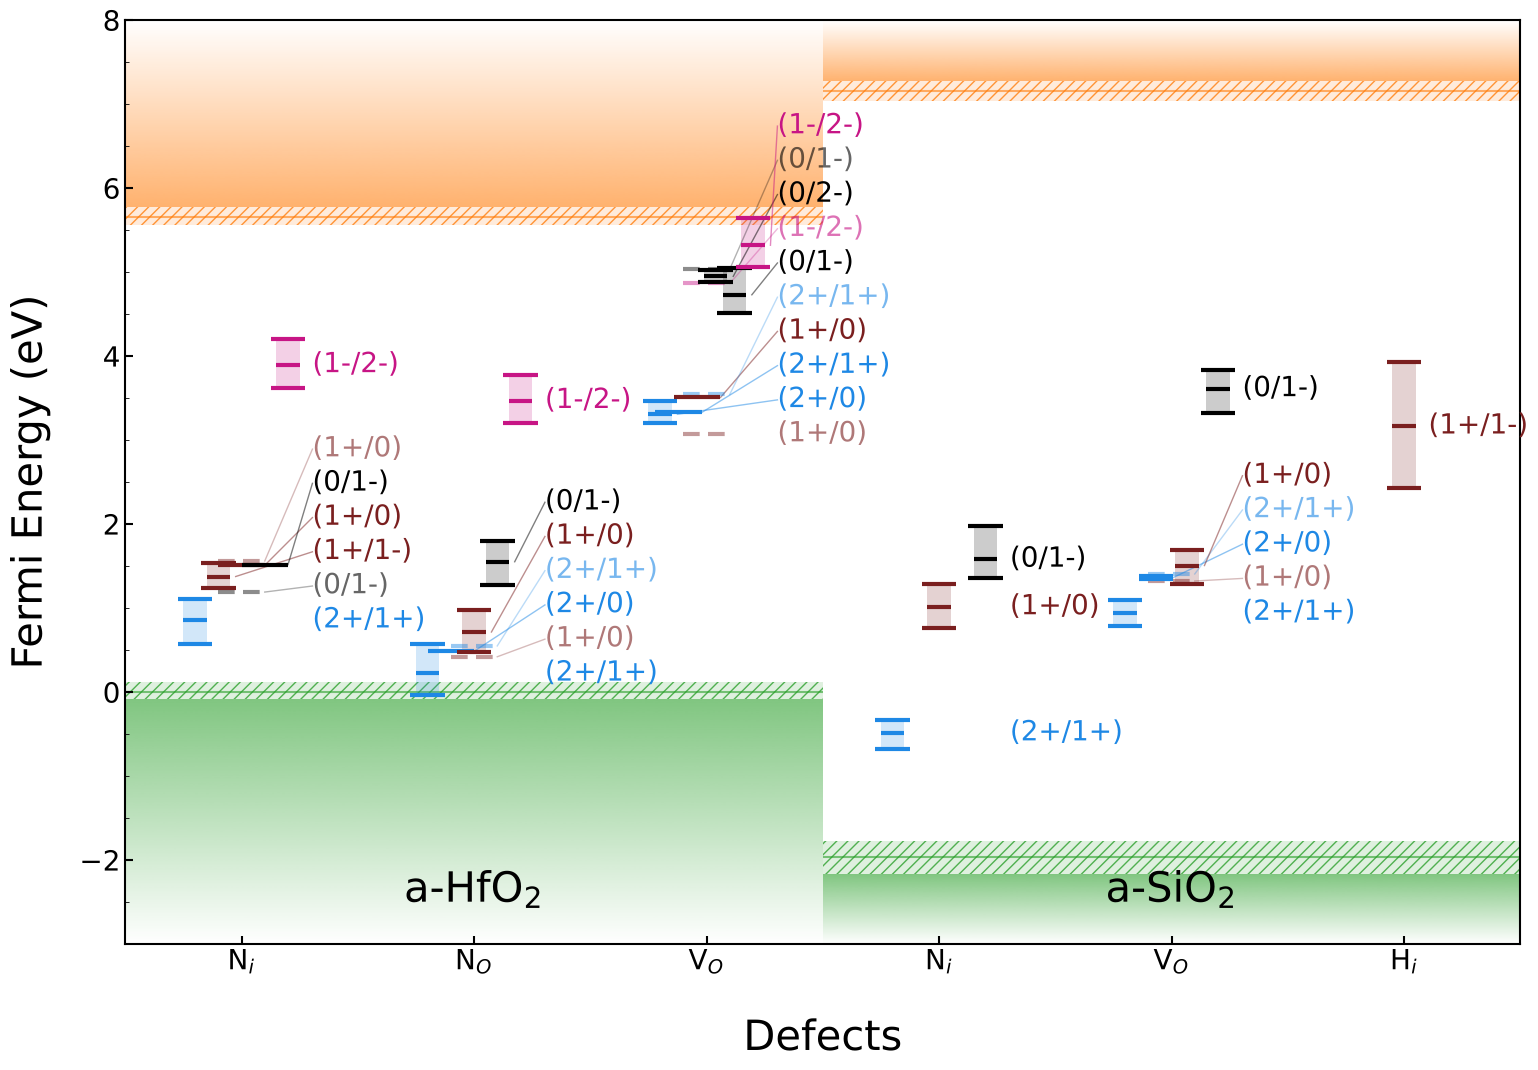

In [11]:
extra = {
    'SiO2': {
        'H$_i$': [CTL('(1+/1-)', 5.1, e_min=4.4, e_max=5.9)],
    },
}

fig, ax, _ = plot_multi_mat_ctl(defects, materials, precomputed_ctls=extra,
                                style=StyleOptions(figsize=(18, 12)))

## 5. Band offsets only

If no defects are passed, `plot_multi_mat_ctl` just draws the band alignment of the materials. It shows each VB and CB placed by its band offset, plus any Fermi levels. Pass an empty list for `defects` and give each `Material` a `Cell` with its band edges. `bulk` is not used here, so any value works.

> The band edges and offsets below are **rough illustrative values** for a Si / SiO$_2$ / HfO$_2$ gate stack, not results from this package.

Text(0, 0.5, 'Energy (eV)')

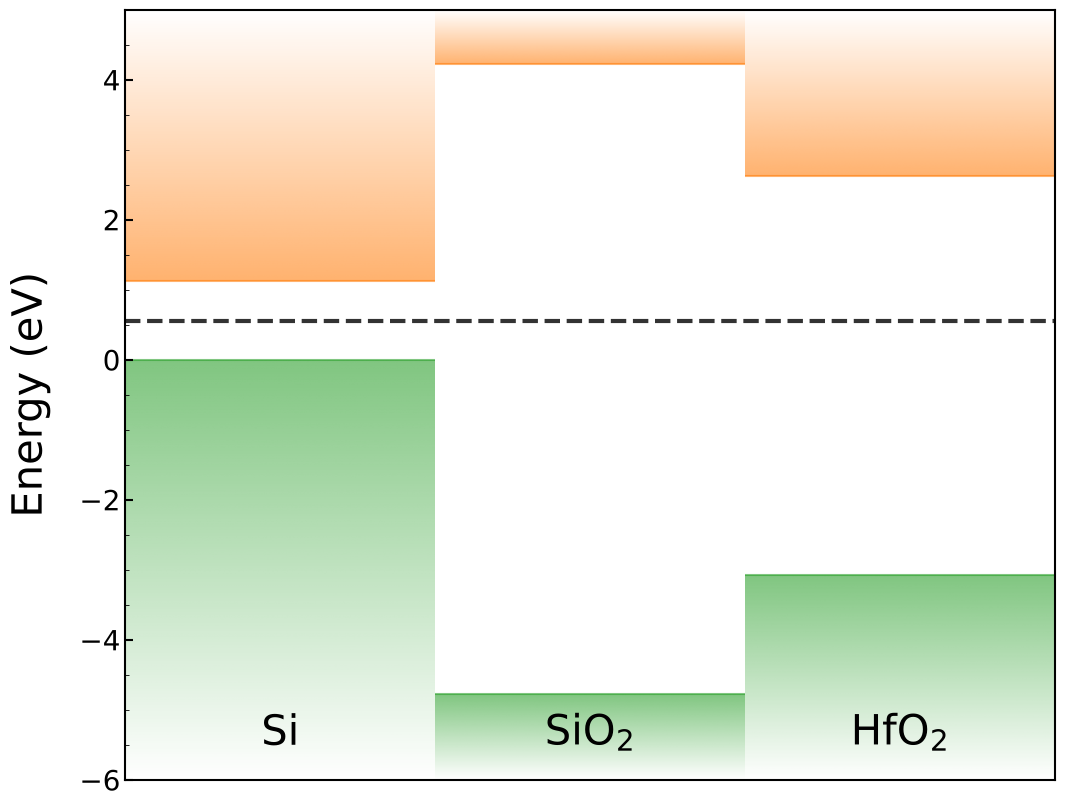

In [12]:
Ha = 27.211386

stack = [
    Material('Si',   cells=[Cell('c', vbm=0.0, cbm=1.12 / Ha, bulk=0.0)], offset=0.0),   # reference
    Material('SiO2', cells=[Cell('c', vbm=0.0, cbm=9.0 / Ha,  bulk=0.0)], offset=3.1),
    Material('HfO2', cells=[Cell('c', vbm=0.0, cbm=5.7 / Ha,  bulk=0.0)], offset=1.5),
]

fig, ax, _ = plot_multi_mat_ctl([], stack,
                                fermi_lines=FermiLevel('Si E$_F$', 0.56, colour='k'),
                                style=StyleOptions(figsize=(12, 10)),
                                xlabel=False, show=False)
ax.set_ylabel('Energy (eV)', size=30)   # the y-axis label assumes CTLs, so relabel it here